# Распределения и схемы цензурирования для Sepsis: терминал Discharge

Пример запуска библиотеки `survpm` (лежит рядом, в `dima/survpm/`).
Библиотека оценивает распределения времён переходов и строит схемы 4.1 и 4.2
из `petri_net_time_estimation_sepsis.ipynb`.

**Модель по умолчанию (Sepsis):**
* состояния — группы событий `event_group` из `Med_Eremina/Sepsis Cases - Event Log_grouped.csv`;
* старт — первая `Registration`, терминал — первая `Discharge` (Release A–E);
* трасса без выписки — правая цензура с причиной `lost` («запись оборвалась»).

## Как запустить на своём журнале

**1. Установить зависимости** (один раз):

```bash
pip install -e "survpm[pm4py]" matplotlib   # из папки dima/
brew install graphviz        # macOS; на Windows — установщик с graphviz.org, папку bin добавить в PATH
```

**2. Подготовить журнал.** Подходит CSV или XES, где одна строка — одно событие, и есть три колонки:

| Что | Пример в Sepsis | Смысл |
|---|---|---|
| номер трассы | `case_id` | один пациент / заявка / объект |
| состояние | `event_group` | активность или группа активностей |
| время | `time:timestamp` | когда произошло событие; любой формат, который понимает `pd.to_datetime` |

Остальные колонки игнорируются. У XES-файлов колонки стандартные:
`case:concept:name`, `concept:name`, `time:timestamp`.

**3. Заполнить ячейку «Настройки»** ниже — это единственное место, которое нужно менять:

* `LOG_PATH` — путь к файлу (`.csv` или `.xes`);
* `CSV_SEP` — разделитель CSV (`","` или `";"`);
* `CASE_COLUMN`, `ACTIVITY_COLUMN`, `TIMESTAMP_COLUMN` — имена трёх колонок;
* `START` — состояние, от которого отсчитывается время; события до него отбрасываются,
  трассы без него исключаются;
* `TERMINAL` — событие-исход; трасса, не дошедшая до него, считается цензурированной;
* `CENSOR_REASON`, `REASON_LABELS` — код причины цензуры и её подпись на схемах;
* `MIN_DURATION_DAYS` — минимальная длительность интервала (одинаковые timestamp);
* `OUTPUT_DIR` — куда сохранить рисунки и таблицы.

Значения активностей должны совпадать с данными посимвольно: список всех состояний
печатается после загрузки (раздел 1) — по нему удобно выбрать `START` и `TERMINAL`.

**4. Запустить все ячейки** (*Run All*). Ноутбук открывается из папки `dima/`
или из корня репозитория. Время во всех таблицах и графиках — в днях.

**Частые ошибки:**
* `KeyError: Нет колонок …` — неверные имена колонок; ошибка печатает, какие колонки есть в файле;
* `ни одна трасса не содержит START` / `не дошла до TERMINAL` — значение не совпадает с данными;
* все колонки слиплись в одну — неверный `CSV_SEP`;
* `ExecutableNotFound: dot` — не установлена программа graphviz (шаг 1).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from IPython.display import display

# survpm лежит в dima/survpm/; путь не нужен, если библиотека установлена через pip install -e survpm
dima_dir = Path.cwd() if Path("survpm").exists() else Path.cwd() / "dima"
sys.path.insert(0, str(dima_dir / "survpm" / "src"))
import survpm
from survpm import adapters, viz
from survpm.distributions import scipy_args

pm4py.util.constants.SHOW_PROGRESS_BAR = False



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [2]:
# ===== Настройки: для своего журнала меняйте только эту ячейку =====
LOG_PATH = dima_dir.parent / "Med_Eremina" / "Sepsis Cases - Event Log_grouped.csv"   # .csv или .xes
CSV_SEP = ","                          # разделитель CSV; для XES не используется
CASE_COLUMN = "case_id"                # номер трассы
ACTIVITY_COLUMN = "event_group"        # состояние
TIMESTAMP_COLUMN = "time:timestamp"    # время события

START = "Registration"                 # отсчёт времени — с первого такого состояния в трассе
TERMINAL = "Discharge"                 # событие-исход; трасса без него — цензура
CENSOR_REASON = "lost"
REASON_LABELS = {"lost": "запись оборвалась"}
MIN_DURATION_DAYS = 1 / 1440           # 1 минута вместо нулевых интервалов
OUTPUT_DIR = dima_dir / "notebooks" / "output" / "censored_petri_discharge"

## 1. Журнал

Читаем CSV (`survpm.read_csv`) или XES (`pm4py.read_xes`) и оставляем три колонки
`case_id, activity, timestamp`. `survpm.prepare` начинает трассу с первого `START`
(трассы без него исключаются), обрезает её после первого `TERMINAL` и схлопывает
соседние повторы состояния. Трасса без `TERMINAL` — цензурированная с причиной `CENSOR_REASON`.

In [3]:
LOG_PATH = Path(LOG_PATH)
if LOG_PATH.suffix.lower() == ".xes":
    raw = pm4py.read_xes(str(LOG_PATH))[[CASE_COLUMN, ACTIVITY_COLUMN, TIMESTAMP_COLUMN]]
    raw = raw.set_axis(["case_id", "activity", "timestamp"], axis=1).astype({"case_id": str, "activity": str})
    raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
else:
    raw = survpm.read_csv(LOG_PATH, CASE_COLUMN, ACTIVITY_COLUMN, TIMESTAMP_COLUMN, sep=CSV_SEP)
print("Состояния в журнале:", raw["activity"].value_counts().to_dict())

log, cases = survpm.prepare(raw, START, TERMINAL, reason=CENSOR_REASON)
if not cases["event"].any():
    raise ValueError(f"Ни одна трасса не дошла до TERMINAL={TERMINAL!r}")
n_traces = raw["case_id"].nunique()
print(f"Трасс: {n_traces}; без {START} исключено: {n_traces - len(cases)}; "
      f"в модели: {len(cases)}; событий: {len(log)}")

Состояния в журнале: {'Examination': 8111, 'Treatment': 1576, 'Admission': 1299, 'Registration': 1050, 'Discharge': 782, 'Return': 294}


Трасс: 1050; без Registration исключено: 0; в модели: 1050; событий: 5872


## 2. Интервалы и вероятности цензуры

`survpm.intervals` строит завершённые интервалы между соседними состояниями и добавляет
цензурированное последнее ожидание для трасс без выписки.
Интервалы с одинаковыми timestamp заменяются на 1 минуту (`min_duration`): плотности
lognormal, gamma и weibull в нуле не определены. Время — в днях.
`censoring_summary` считает вероятности **за одно ожидание** в состоянии:
`p_completed` — переход зарегистрирован, `q_lost` — запись оборвалась.

In [4]:
intervals = survpm.intervals(log, cases, MIN_DURATION_DAYS)
display(intervals.head())
censored = intervals.loc[~intervals.observed]
print(f"Завершённых интервалов: {intervals.observed.sum()}; цензурированных: {len(censored)}")
summary = survpm.censoring_summary(intervals)
display(summary.round(4))

,case_id,src,dst,duration,observed,reason
0,A,Registration,Examination,0.007859,True,
1,A,Examination,Treatment,0.108877,True,
2,A,Treatment,Admission,0.006620,True,
3,A,Admission,Examination,1.782419,True,
4,A,Examination,Discharge,9.302083,True,


Завершённых интервалов: 4822; цензурированных: 268


,src,n_visits,n_completed,p_completed,q_censored,n_lost,q_lost
0,Admission,1097,1084,0.9881,0.0119,13,0.0119
1,Examination,1960,1841,0.9393,0.0607,119,0.0607
2,Registration,1050,1014,0.9657,0.0343,36,0.0343
3,Treatment,983,883,0.8983,0.1017,100,0.1017


## 3. Оценка распределений времён переходов

**Шаг 1. Семейство.** `CensoredStateNet.fit` сначала для каждого ребра подбирает MLE exponential,
lognormal, gamma, weibull по завершённым интервалам и выбирает минимальный AIC
(в таблице — `ΔAIC` от лучшего; 0 — выбранное). Ребро с менее чем тремя
завершениями получает exponential.

**Шаг 2. Параметры.** `CensoredStateNet.fit` для каждого состояния совместно оценивает
вероятности выбора выходов π и параметры их распределений, максимизируя правдоподобие
с цензурой: завершённый интервал даёт $p_{sd} f_{sd}(t)$, цензурированный —
$\sum_d p_{sd} S_{sd}(c)$. Для сравнения — наивная оценка только по завершённым
(`use_censoring=False`). Подробности формул — в разделе 3 `petri_net_time_estimation_sepsis.ipynb`.

In [5]:
model = survpm.CensoredStateNet(START, TERMINAL, min_duration=MIN_DURATION_DAYS).fit(intervals=intervals)
naive = survpm.CensoredStateNet(START, TERMINAL, use_censoring=False,
                                families=model.families_).fit(intervals=intervals)
families, aic_table = model.families_, model.aic_table_
estimates, naive_estimates = model.edges_, naive.edges_
display(aic_table.pivot_table(index=["src", "dst", "n_completed"], columns="family",
                              values="delta_aic").round(1))
display(model.diagnostics_)

estimate_table = model.edges_table().merge(
    naive.edges_table()[["transition", "p", "mean_days"]].rename(columns={"p": "p_naive",
                                                                           "mean_days": "mean_days_naive"}),
    on="transition")
display(estimate_table.round(4))

family                                exponential  gamma  lognormal  weibull
src          dst         n_completed                                        
Admission    Discharge   139                 20.1    1.4       40.3      0.0
             Examination 916                 30.3    4.8      228.5      0.0
             Treatment   29                  13.3    0.0       18.9      6.0
Examination  Admission   499                598.2  240.2        0.0    126.4
             Discharge   637                  8.0    0.0       53.1      5.7
             Treatment   705                 12.0    0.0      172.6      6.0
Registration Admission   7                    0.0    0.3        0.6      0.2
             Examination 758                397.7   31.3        0.0    105.3
             Treatment   249                 40.5   33.6        0.0     42.0
Treatment    Admission   591                446.0    0.0       28.4     12.1
             Discharge   6                    0.0    0.8        4.7      1.4
             Examination 286                804.0  288.1        0.0    142.1

,src,success,status,n_completed,n_censored,nll,message,at_boundary
0,Admission,True,ok,1084,13,2005.068523,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,False
1,Examination,True,ok,1841,119,2995.196590,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,False
2,Registration,True,ok,1014,36,-2669.209414,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,False
3,Treatment,True,ok,883,100,-1440.587311,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,False


,transition,src,dst,p,distribution,n_completed,mean_days,median_days,q90_days,p_naive,mean_days_naive
0,Admission→Discharge,Admission,Discharge,0.1282,"weibull(shape=1.39316, scale=3.691)",139,3.3667,2.8372,6.7164,0.1282,3.3667
1,Admission→Examination,Admission,Examination,0.8450,"weibull(shape=1.16385, scale=1.39677)",916,1.3248,1.0194,2.8599,0.8450,1.3248
2,Admission→Treatment,Admission,Treatment,0.0267,"gamma(shape=0.471384, scale=1.21495)",29,0.5727,0.2468,1.5682,0.0268,0.5725
3,Examination→Admission,Examination,Admission,0.2711,"lognormal(median=0.31213, sigma=1.67757)",499,1.2748,0.3121,2.6793,0.2710,1.2695
4,Examination→Discharge,Examination,Discharge,0.3472,"gamma(shape=1.1773, scale=4.6504)",637,5.4749,4.0260,12.1084,0.3460,5.4731
5,Examination→Treatment,Examination,Treatment,0.3816,"gamma(shape=0.849275, scale=0.0905451)",705,0.0769,0.0496,0.1843,0.3829,0.0768
6,Registration→Admission,Registration,Admission,0.0069,exponential(mean=0.11956),7,0.1196,0.0829,0.2753,0.0069,0.1195
7,Registration→Examination,Registration,Examination,0.7476,"lognormal(median=0.0162862, sigma=0.604894)",758,0.0196,0.0163,0.0354,0.7475,0.0196
8,Registration→Treatment,Registration,Treatment,0.2455,"lognormal(median=0.00886657, sigma=0.935473)",249,0.0137,0.0089,0.0294,0.2456,0.0137
9,Treatment→Admission,Treatment,Admission,0.6657,"gamma(shape=0.429955, scale=0.130305)",591,0.0560,0.0220,0.1562,0.6693,0.0533


Гистограмма — завершённые интервалы ребра; линии — оценённые плотности.
Ось X ограничена 98% квантилем наблюдаемых времён.

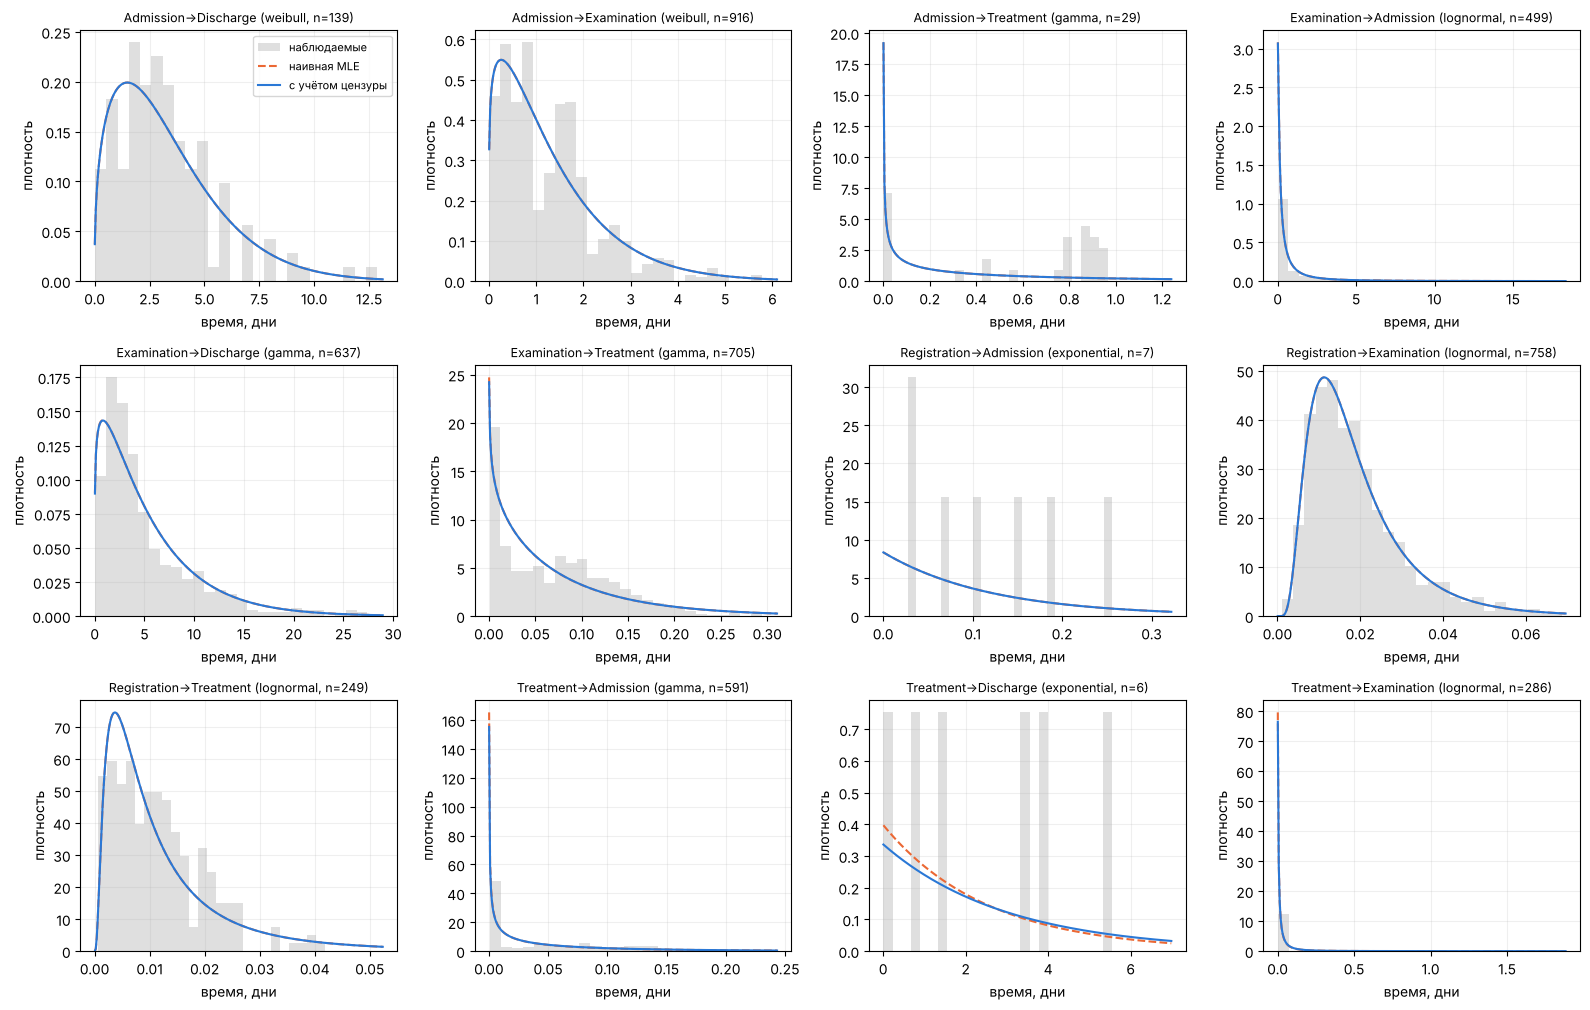

In [6]:
lookup = {(t["src"], t["dst"]): t for t in estimates}
naive_lookup = {(t["src"], t["dst"]): t for t in naive_estimates}
edges = sorted(lookup)
n_cols = 4
n_rows = -(-len(edges) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.4 * n_rows))
for ax, edge in zip(axes.flat, edges):
    observed = intervals.loc[intervals.observed & (intervals.src == edge[0]) & (intervals.dst == edge[1]), "duration"]
    upper = np.quantile(observed, .98)
    x = np.linspace(upper * 1e-3, upper * 1.3, 300)
    ax.hist(observed[observed <= upper * 1.3], bins=25, density=True, alpha=.25, color="gray", label="наблюдаемые")
    for label, fitted, color, style in [("наивная MLE", naive_lookup, "#eb6834", "--"),
                                        ("с учётом цензуры", lookup, "#2a78d6", "-")]:
        rv, args, kwargs = scipy_args(fitted[edge]["dist"])
        ax.plot(x, rv.pdf(x, *args, **kwargs), color=color, ls=style, label=label)
    ax.set_title(f"{edge[0]}→{edge[1]} ({families[edge]}, n={len(observed)})", fontsize=9)
    ax.set(xlabel="время, дни", ylabel="плотность")
    ax.grid(alpha=.2)
for ax in axes.flat[len(edges):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. Схема 4.1: сеть состояний и фишка в CENS

`model.to_pm4py()` строит сеть с одним токеном: места — состояния, переходы — наблюдаемые
пары `src→dst`, тихие переходы `src→CENS:lost` — обрывы записи. На обычных переходах —
оценённая π выбора, наблюдаемая доля `p наблюд.` и распределение времени.
`adapters.replay_censored` проигрывает путь первой цензурированной трассы и её обрыв;
в результате одна фишка лежит в `CENS`.

AA: Registration → Examination → Treatment → CENS


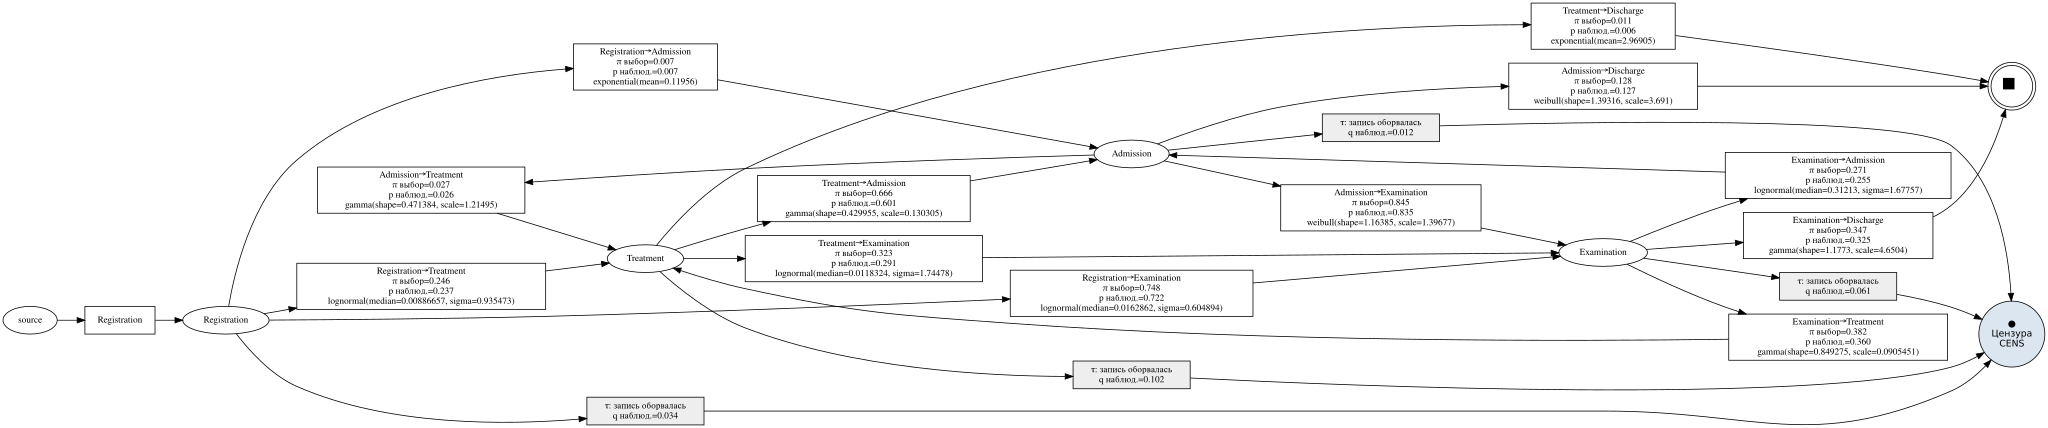

In [7]:
net, im, fm = model.to_pm4py()

example_case = censored.case_id.iloc[0]
states = log.loc[log.case_id == example_case, "activity"].tolist()
marking = adapters.replay_censored(net, im, states, reason=CENSOR_REASON)
print(f"{example_case}: {' → '.join(states)} → CENS")

snapshot = adapters.draw_state_net(net, marking, fm, reason_labels=REASON_LABELS)
display(snapshot)

## 5. Схема 4.2: граф состояний с отдельной цензурой

На обычных стрелках — `p наблюд.`, на пунктирной стрелке в `CENS` — `q`.
Сумма выходов из каждого состояния равна единице.

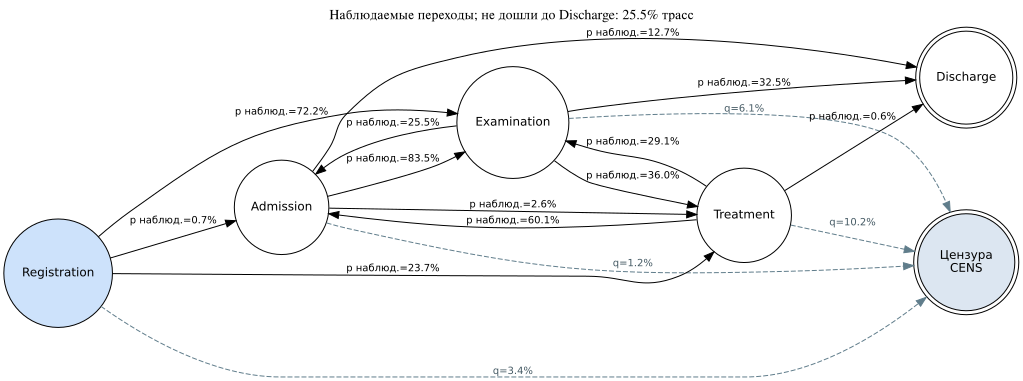

In [8]:
graph = viz.state_graph(intervals, START, TERMINAL, reason_labels=REASON_LABELS,
                        title=f"Наблюдаемые переходы; не дошли до {TERMINAL}: {1 - cases.event.mean():.1%} трасс")
display(graph)

## 6. Сохранение рисунков и оценок

In [9]:
figure_dir = Path(OUTPUT_DIR)
figure_dir.mkdir(parents=True, exist_ok=True)
for name, picture in [("censored_marking", snapshot), ("observed_states_with_censoring", graph)]:
    for fmt in ("png", "svg"):
        (figure_dir / f"{name}.{fmt}").write_bytes(picture.pipe(format=fmt))
summary.to_csv(figure_dir / "censoring_probabilities.csv", index=False)
estimate_table.to_csv(figure_dir / "edge_estimates.csv", index=False)
aic_table.to_csv(figure_dir / "family_aic.csv", index=False)
print("Сохранено:", figure_dir.resolve())

Сохранено: /tmp/nbrun/dima/notebooks/output/censored_petri_discharge
